# Signed distance fields, drawn the way a marble would feel them

A visual notebook for the Marble Madness SDF remake. Every course in this game — the ramp, the chute, the wave, the portal, the crater you blast at runtime — is one function

$$d(\mathbf{p}, t)$$

The picture on screen and the solid the marble hits are that same function. This notebook walks the idea the way a short explainer video walks an idea: open on a picture that is slightly wrong, rebuild the definition from one shape, change a single term, and watch the marble's life get better or worse.

**The video this pacing is stolen from** is not an SDF video. It is Jia-Bin Huang's [*Your Softmax Is Broken. Here's the Fix.*](https://www.youtube.com/watch?v=dYxEmKbZfr4) (channel [@jbhuang0604](https://www.youtube.com/@jbhuang0604)). YouTube blocked timed transcript downloads from this machine (`youtube-transcript-api` and `yt-dlp` both got a bot check). The full spoken narration was recovered from the public watch-page text instead. The video has no published chapter list. Its rhythm, in our own words:

1. Open on a number the computer got wrong (a loss that should be tiny and comes back as exact zero), before defining anything.
2. Show that the wrong number changes a real outcome (a modular-addition loss that spikes).
3. Rebuild the object from scratch, one picture, then one line.
4. Name the failure ("the precision cliff") and sweep **one** variable until you can see it.
5. Change the algebra so the small quantity is computed directly. Same axes. The curve stays on the truth.
6. Answer "but that term is tiny, who cares?" with the thing that *amplifies* it (Adam).
7. Close on one sentence that covers both bugs.

Chapters below copy that rhythm onto the math this game actually runs: primitives and ramps, smooth CSG, sphere tracing, the 120 Hz loop, portals, and the `FieldMutation` ring buffer. Formulas match `docs/sdf-marble-research.md`, `docs/gameplay-feel-bible.md`, and the Playtest Build 0 kernel in `src/sdf/eval-cpu.ts`.

Constants used when a plot needs a number from the running game (`src/contracts/physics.ts`):

| symbol | value | where |
| :--- | :--- | :--- |
| marble radius $R$ | `0.55` | `DEFAULT_PHYSICS_CONFIG.marbleRadius` |
| fixed step | `1/120` s | `fixedDt` |
| gravity | `35` | Build 0 tuner (the feel bible's heavier arcade target is $g = 120$) |
| shatter speed | `31` | `shatterImpactSpeed` |
| track friction $\mu$ | `1.85` | `MATERIAL_PROPERTIES.standard` |
| ice friction $\mu$ | `0.12` | `MATERIAL_PROPERTIES.ice` |


In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle, FancyArrowPatch, Polygon

MEDIA = Path("/cursor/stores/bc-07436942-d7b2-4c7b-9bb2-9c96a9f41e4d/media")
MEDIA.mkdir(parents=True, exist_ok=True)
METRICS_PATH = Path("/tmp/sdf-notebook-metrics.json")

INK = "#e8f1ff"
MUTED = "#93a4c3"
AMBER = "#fbbf24"
CYAN = "#67e8f9"
PINK = "#fb7185"
MINT = "#34d399"
ORANGE = "#fb923c"
BLUE = "#60a5fa"
ZERO = "#f8fafc"
BG = "#0b1020"
PANEL = "#10182e"

R_MARBLE = 0.55
DT = 1.0 / 120.0
G_BUILD = 35.0
G_BIBLE = 120.0
MU_TRACK = 1.85
MU_ICE = 0.12
MU_STICKY = 7.5

SDF_CMAP = LinearSegmentedColormap.from_list(
    "sdf_iq",
    ["#4c1d95", "#be185d", "#fb7185", "#f8fafc", "#7dd3fc", "#0284c7", "#082f49"],
)

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "axes.edgecolor": "#334155",
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.titlecolor": INK,
    "font.size": 11,
    "savefig.facecolor": BG,
    "savefig.bbox": "tight",
})

METRICS = {}


def metric(key, value):
    if isinstance(value, (np.floating, np.integer)):
        value = value.item()
    METRICS[key] = value
    print(f"{key}: {value}")


def finish(fig, name):
    path = MEDIA / f"{name}.png"
    fig.savefig(path, dpi=140, facecolor=fig.get_facecolor())
    display(fig)
    plt.close(fig)
    print(f"saved {path.name}")


def dress(ax, title, equal=True):
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=8)
    if equal:
        ax.set_aspect("equal", adjustable="box")
    ax.tick_params(labelsize=8)
    for spine in ax.spines.values():
        spine.set_color("#334155")


def mesh(xlim, ylim, n=360):
    xs = np.linspace(xlim[0], xlim[1], n)
    ys = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(xs, ys)
    return X, Y


def as_field(fn, X, Y):
    P = np.column_stack([X.ravel(), Y.ravel()])
    return fn(P).reshape(X.shape)


def add_sdf(ax, X, Y, D, title, v=None):
    if v is None:
        v = max(float(np.percentile(np.abs(D), 97)), 0.35)
    levels = np.linspace(-v, v, 33)
    cf = ax.contourf(X, Y, D, levels=levels, cmap=SDF_CMAP, extend="both")
    ax.contour(X, Y, D, levels=np.linspace(-v, v, 9), colors="#dbe7ff", linewidths=0.35, alpha=0.45)
    ax.contour(X, Y, D, levels=[0.0], colors=[ZERO], linewidths=2.1)
    dress(ax, title)
    return cf


def colorbar(fig, cf, ax, label="signed distance  d(p)"):
    cb = fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label(label, color=INK, fontsize=9)
    cb.ax.tick_params(colors=MUTED, labelsize=8)
    cb.outline.set_edgecolor("#334155")
    return cb


def grad2(fn, P, h=1e-3):
    P = np.asarray(P, float)
    dx = fn(P + np.array([h, 0.0])) - fn(P - np.array([h, 0.0]))
    dy = fn(P + np.array([0.0, h])) - fn(P - np.array([0.0, h]))
    return np.column_stack([dx, dy]) / (2.0 * h)


def normal_quiver(ax, fn, xlim, ylim, n=24, band=0.12, color=AMBER, scale=3.1):
    xs = np.linspace(xlim[0], xlim[1], n)
    ys = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(xs, ys)
    P = np.column_stack([X.ravel(), Y.ravel()])
    D = fn(P)
    G = grad2(fn, P)
    mag = np.linalg.norm(G, axis=1, keepdims=True)
    U = G / np.maximum(mag, 1e-8)
    m = np.abs(D) < band
    if not np.any(m):
        return
    ax.quiver(
        P[m, 0], P[m, 1], U[m, 0], U[m, 1],
        angles="xy", scale_units="xy", scale=scale,
        color=color, width=0.004, zorder=5, pivot="tail",
    )


def top_surface(fn, xs, ylim, n=480):
    ys = np.linspace(ylim[0], ylim[1], n)
    out = np.full(len(xs), np.nan)
    for i, x in enumerate(xs):
        P = np.column_stack([np.full(n, x), ys])
        d = fn(P)
        cross = np.where((d[:-1] <= 0.0) & (d[1:] > 0.0))[0]
        if len(cross) == 0:
            continue
        k = int(cross[-1])
        denom = d[k] - d[k + 1]
        t = 0.0 if abs(denom) < 1e-12 else float(np.clip(d[k] / denom, 0.0, 1.0))
        out[i] = ys[k] + t * (ys[k + 1] - ys[k])
    return out


def draw_marble(ax, c, r=R_MARBLE, color=ZERO):
    ax.add_patch(Circle(c, r, fill=False, ec=color, lw=1.8, zorder=6))
    ax.add_patch(Circle(c, 0.045, fc=color, ec=color, zorder=6))


def sd_circle(P, r=1.0, center=(0.0, 0.0)):
    return np.linalg.norm(P - np.asarray(center, float), axis=1) - r


def sd_box(P, b, center=(0.0, 0.0)):
    q = np.abs(P - np.asarray(center, float)) - np.asarray(b, float)
    return np.linalg.norm(np.maximum(q, 0.0), axis=1) + np.minimum(np.max(q, axis=1), 0.0)


def sd_round_box(P, b, r, center=(0.0, 0.0)):
    b = np.maximum(np.asarray(b, float) - r, 1e-3)
    return sd_box(P, b, center=center) - r


def sd_capsule(P, a, b, r):
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    pa = P - a
    ba = b - a
    h = np.clip((pa @ ba) / max(float(np.dot(ba, ba)), 1e-8), 0.0, 1.0)
    return np.linalg.norm(pa - np.outer(h, ba), axis=1) - r


def sd_ramp(P, half_len=2.15, rise=1.7, thickness=0.42):
    # Side-view axial ramp. Run is x, up is y. Lip thickness never collapses to a knife.
    x = P[:, 0]
    y = P[:, 1]
    safe = max(half_len, 0.01)
    tan = (0.5 * rise) / safe
    cos_t = 1.0 / np.sqrt(1.0 + tan * tan)
    y_top = (x / safe) * (0.5 * rise)
    half_thick = max(0.075, 0.5 * thickness)
    d_run = np.abs(x) - safe
    d_y = (np.abs(y - (y_top - half_thick)) - half_thick) * cos_t
    q = np.column_stack([d_run, d_y])
    return np.linalg.norm(np.maximum(q, 0.0), axis=1) + np.minimum(np.max(q, axis=1), 0.0)


def op_union(a, b):
    return np.minimum(a, b)


def op_smooth_union(a, b, k):
    # Quadratic polynomial smooth-min used by src/sdf/eval-cpu.ts
    k = max(float(k), 1e-4)
    h = np.maximum(k - np.abs(a - b), 0.0) / k
    return np.minimum(a, b) - 0.25 * h * h * k


def op_sub(a, b):
    return np.maximum(a, -b)


def op_smooth_sub(a, b, k):
    k = max(float(k), 1e-4)
    h = np.maximum(k - np.abs(a + b), 0.0) / k
    return np.maximum(a, -b) + 0.25 * h * h * k


def support_ny(fn, xlim, ylim, band=0.08):
    xs = np.linspace(xlim[0], xlim[1], 70)
    ys = np.linspace(ylim[0], ylim[1], 90)
    X, Y = np.meshgrid(xs, ys)
    P = np.column_stack([X.ravel(), Y.ravel()])
    D = fn(P)
    G = grad2(fn, P)
    mag = np.linalg.norm(G, axis=1)
    ny = G[:, 1] / np.maximum(mag, 1e-8)
    m = np.abs(D) < band
    if not np.any(m):
        return float("nan")
    return float(np.min(ny[m]))


print("helpers ready", "R", R_MARBLE, "dt", round(DT, 6))


helpers ready R 0.55 dt 0.008333


## Chapter 1 — What is a signed distance field?

Here is the whole definition, before the formula. Pick a point. Ask one question: *how far to the surface, and which side am I on?*

- outside, the answer is positive
- on the skin, the answer is zero
- inside the solid, the answer is negative

A circle of radius 1 centered at the origin is the cleanest place to see it, because you already know the answer: $\|\mathbf{p}\| - 1$. The white curve in the next figure is the only place a marble is allowed to *touch*. The pink side is stone. The blue side is air.

Then the property that makes physics cheap. Walk one step along the gradient and the value of $d$ changes by exactly the length of that step:

$$\|\nabla d(\mathbf{p})\| = 1$$

That is the eikonal equation. It is why "push the center out by $R - d$" lands on the surface in a single correction, instead of a guess.


ch1_eikonal_median_abs_err: 4.1977534614989764e-08
ch1_eikonal_p95_abs_err: 3.800851304247544e-07


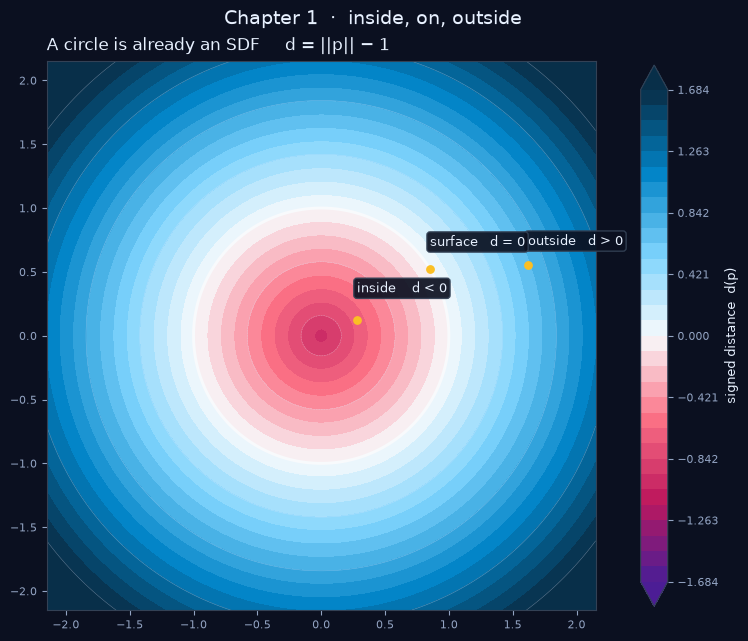

saved sdf-ch1-circle-isocontours.png
ch1_true_push: 0.8
ch1_squared_push: 0.9875
ch1_true_residual_d_minus_R: 0.0
ch1_squared_residual_d_minus_R: 0.1875


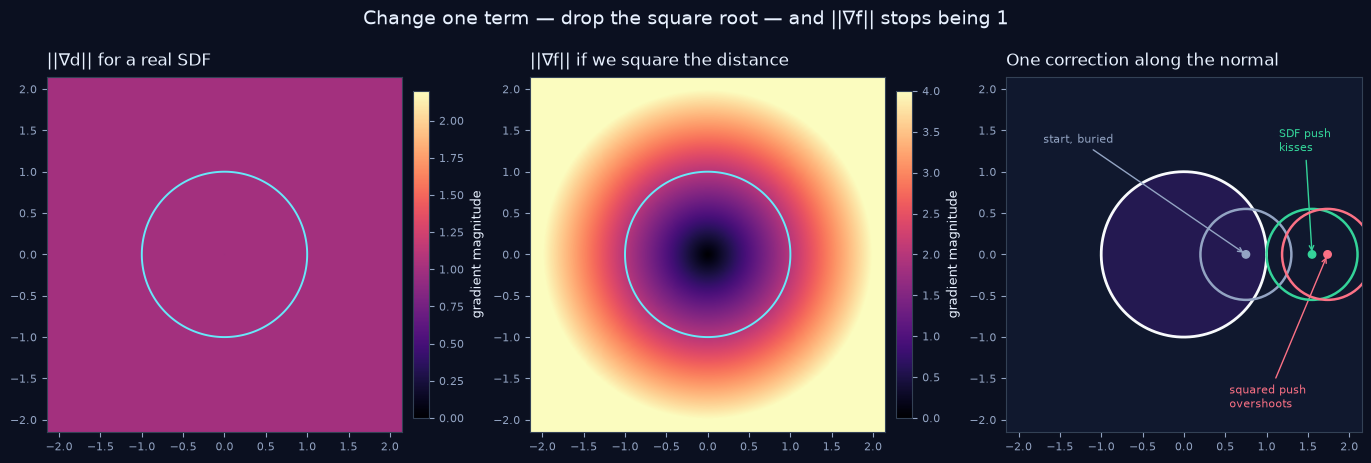

saved sdf-ch1-eikonal-vs-squared.png


In [2]:
# --- The circle, then the one-term break: drop the square root ---
xlim, ylim = (-2.15, 2.15), (-2.15, 2.15)
X, Y = mesh(xlim, ylim, n=380)
P = np.column_stack([X.ravel(), Y.ravel()])

def sd_true(Q):
    return sd_circle(Q, r=1.0)

def sd_squared(Q):
    # Same zero set. Not a distance. "What if we drop the square root?"
    return np.sum(Q * Q, axis=1) - 1.0

D = sd_true(P).reshape(X.shape)
G = grad2(sd_true, P)
gn = np.linalg.norm(G, axis=1)
rad = np.linalg.norm(P, axis=1)
mask = rad > 0.2
metric("ch1_eikonal_median_abs_err", float(np.median(np.abs(gn[mask] - 1.0))))
metric("ch1_eikonal_p95_abs_err", float(np.percentile(np.abs(gn[mask] - 1.0), 95)))

fig, ax = plt.subplots(figsize=(7.4, 6.3), constrained_layout=True)
cf = add_sdf(ax, X, Y, D, "A circle is already an SDF     d = ||p|| − 1")
# Mark the three answers the way the video marks a single example.
for (pt, text, dy) in [
    ((1.62, 0.55), "outside   d > 0", 0.16),
    ((np.cos(0.55), np.sin(0.55)), "surface   d = 0", 0.18),
    ((0.28, 0.12), "inside    d < 0", 0.22),
]:
    ax.scatter([pt[0]], [pt[1]], s=28, c=AMBER, zorder=6)
    ax.text(pt[0], pt[1] + dy, text, color=INK, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.25", fc=BG, ec="#334155", alpha=0.92))
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
colorbar(fig, cf, ax)
fig.suptitle("Chapter 1  ·  inside, on, outside", fontsize=14, color=INK)
finish(fig, "sdf-ch1-circle-isocontours")

# One-step depenetration: eikonal SDF kisses; squared "distance" overshoots.
center0 = np.array([0.75, 0.0])
d_true = float(sd_true(center0[None])[0])
d_sq = float(sd_squared(center0[None])[0])
push_true = R_MARBLE - d_true
push_sq = R_MARBLE - d_sq
center_true = center0 + np.array([push_true, 0.0])
center_sq = center0 + np.array([push_sq, 0.0])
metric("ch1_true_push", push_true)
metric("ch1_squared_push", push_sq)
metric("ch1_true_residual_d_minus_R", float(sd_true(center_true[None])[0]) - R_MARBLE)
metric("ch1_squared_residual_d_minus_R", float(sd_true(center_sq[None])[0]) - R_MARBLE)

Gn_sq = grad2(sd_squared, P)
gn_sq = np.linalg.norm(Gn_sq, axis=1)

fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.7), constrained_layout=True)
for ax, field, title, v in [
    (axes[0], gn.reshape(X.shape), "||∇d|| for a real SDF", 2.2),
    (axes[1], gn_sq.reshape(X.shape), "||∇f|| if we square the distance", 4.0),
]:
    im = ax.imshow(
        field, extent=[xlim[0], xlim[1], ylim[0], ylim[1]], origin="lower",
        cmap="magma", vmin=0.0, vmax=v, interpolation="bilinear",
    )
    ax.contour(X, Y, D, levels=[0.0], colors=[CYAN], linewidths=1.4)
    dress(ax, title)
    colorbar(fig, im, ax, label="gradient magnitude")

ax = axes[2]
theta = np.linspace(0, 2 * np.pi, 240)
ax.plot(np.cos(theta), np.sin(theta), color=ZERO, lw=2.0, label="surface d = 0")
ax.add_patch(Circle((0, 0), 1.0, fc="#4c1d95", alpha=0.35, ec="none"))
draw_marble(ax, center0, color=MUTED)
draw_marble(ax, center_true, color=MINT)
draw_marble(ax, center_sq, color=PINK)
ax.annotate(
    "start, buried",
    xy=center0, xytext=(-1.7, 1.35),
    color=MUTED, fontsize=8, arrowprops=dict(arrowstyle="->", color=MUTED),
)
ax.annotate(
    "SDF push\nkisses",
    xy=center_true, xytext=(1.15, 1.25),
    color=MINT, fontsize=8, arrowprops=dict(arrowstyle="->", color=MINT),
)
ax.annotate(
    "squared push\novershoots",
    xy=center_sq, xytext=(0.55, -1.85),
    color=PINK, fontsize=8, arrowprops=dict(arrowstyle="->", color=PINK),
)
dress(ax, "One correction along the normal")
ax.set_xlim(-2.15, 2.15)
ax.set_ylim(-2.15, 2.15)
fig.suptitle("Change one term — drop the square root — and ||∇f|| stops being 1", fontsize=14, color=INK)
finish(fig, "sdf-ch1-eikonal-vs-squared")


## Chapter 2 — Primitives, ramps, and smooth CSG

A course is not a mesh. It is a handful of these functions, combined.

Hard union is $\min(d_A, d_B)$. That is correct and brutal: where two boxes meet, the normal can swing from "up" to "sideways" in a single sample. A rolling marble reads that swing as a curb. It snags.

The repair used by `evaluateSdfTree` in `src/sdf/eval-cpu.ts` is the quadratic polynomial smooth union. One extra term, controlled by a single length $k$:

$$h = \frac{\max(k - |d_A - d_B|, 0)}{k}, \qquad d = \min(d_A, d_B) - \tfrac14 h^2 k$$

$k = 0$ is the curb. Raise $k$ and that curb becomes a ramp the marble can roll. Smooth subtraction is the same idea with a sign flip, and it is how a banked U-chute is carved out of a ramp without leaving a knife edge for the marble to catch:

$$h = \frac{\max(k - |d_A + d_B|, 0)}{k}, \qquad d = \max(d_A, -d_B) + \tfrac14 h^2 k$$

The GPU shader writes the same fillet in Inigo Quilez's cubic form (`mix` minus $k\,h(1-h)$ in `shader-compiler.ts`). Same picture, different polynomial. The plots below use the CPU quadratic, because that is the field the 120 Hz solver queries.


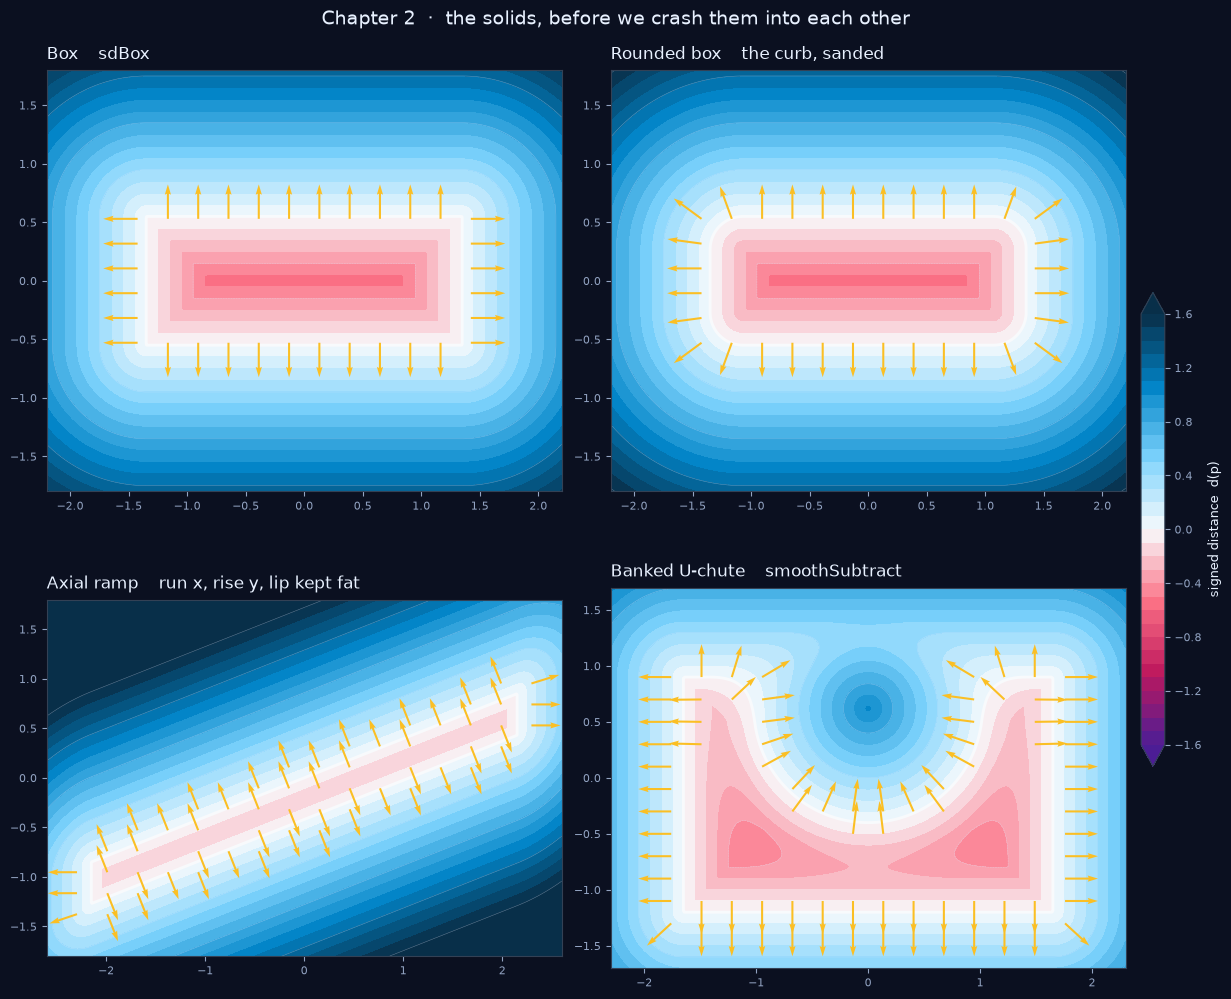

saved sdf-ch2-primitives-ramps.png
ch2_hard_surface_jump: 1.0
ch2_smooth_surface_jump: 0.098737946933388


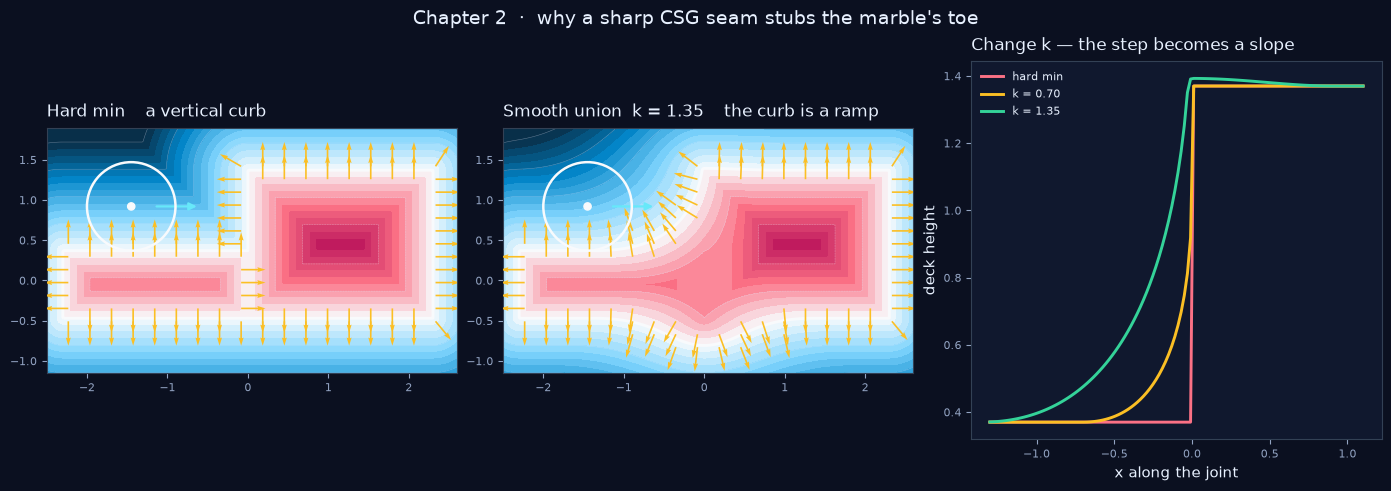

saved sdf-ch2-hard-vs-smooth-seam.png
ch2_chute_hard_min_ny: -1.0
ch2_chute_smooth_min_ny: -1.0


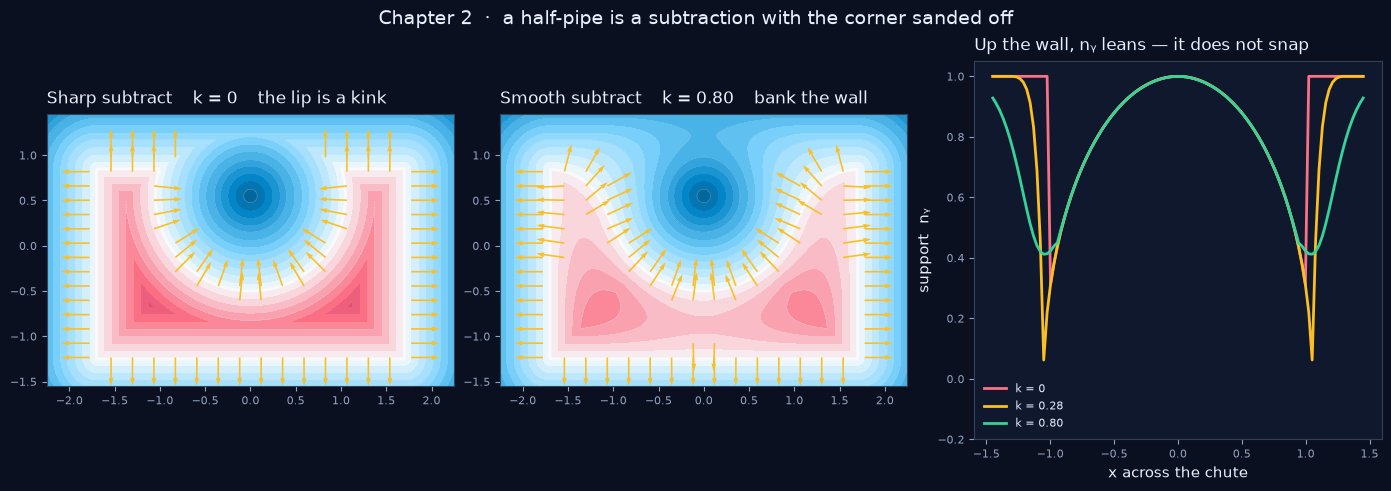

saved sdf-ch2-uchute-fillet.png


In [3]:
# --- Primitives a Marble Madness deck is made of ---
fig, axes = plt.subplots(2, 2, figsize=(12.2, 10.2), constrained_layout=True)
panels = [
    (axes[0, 0], (-2.2, 2.2), (-1.8, 1.8), lambda Q: sd_box(Q, (1.35, 0.55)), "Box    sdBox"),
    (axes[0, 1], (-2.2, 2.2), (-1.8, 1.8), lambda Q: sd_round_box(Q, (1.35, 0.55), 0.28), "Rounded box    the curb, sanded"),
    (axes[1, 0], (-2.6, 2.6), (-1.8, 1.8), lambda Q: sd_ramp(Q), "Axial ramp    run x, rise y, lip kept fat"),
    (axes[1, 1], (-2.3, 2.3), (-1.7, 1.7), lambda Q: op_smooth_sub(
        sd_box(Q, (1.65, 1.05), center=(0.0, -0.15)),
        sd_circle(Q, 1.02, center=(0.0, 0.62)),
        0.42,
    ), "Banked U-chute    smoothSubtract"),
]
for ax, xlim, ylim, fn, title in panels:
    X, Y = mesh(xlim, ylim, n=320)
    D = as_field(fn, X, Y)
    cf = add_sdf(ax, X, Y, D, title, v=1.6)
    normal_quiver(ax, fn, xlim, ylim, n=18, band=0.16, scale=3.4)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
colorbar(fig, cf, axes[:, 1])
fig.suptitle("Chapter 2  ·  the solids, before we crash them into each other", fontsize=14, color=INK)
finish(fig, "sdf-ch2-primitives-ramps")


def step_hard(Q):
    a = sd_box(Q, (1.15, 0.42), center=(-1.15, -0.05))
    b = sd_box(Q, (1.15, 0.92), center=(1.15, 0.45))
    return op_union(a, b)


def step_smooth(Q, k=0.55):
    a = sd_box(Q, (1.15, 0.42), center=(-1.15, -0.05))
    b = sd_box(Q, (1.15, 0.92), center=(1.15, 0.45))
    return op_smooth_union(a, b, k)


xs_seam = np.linspace(-1.3, 1.1, 120)
y_hard = top_surface(step_hard, xs_seam, (-1.2, 2.0))
y_smooth = top_surface(lambda Q: step_smooth(Q, 1.35), xs_seam, (-1.2, 2.0))
metric("ch2_hard_surface_jump", float(np.nanmax(np.abs(np.diff(y_hard)))))
metric("ch2_smooth_surface_jump", float(np.nanmax(np.abs(np.diff(y_smooth)))))

fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.8), constrained_layout=True)
xlim, ylim = (-2.5, 2.6), (-1.15, 1.9)
X, Y = mesh(xlim, ylim, n=340)
for ax, fn, title in [
    (axes[0], step_hard, "Hard min    a vertical curb"),
    (axes[1], lambda Q: step_smooth(Q, 1.35), "Smooth union  k = 1.35    the curb is a ramp"),
]:
    cf = add_sdf(ax, X, Y, as_field(fn, X, Y), title, v=1.35)
    normal_quiver(ax, fn, xlim, ylim, n=20, band=0.16, scale=3.3)
    approach = np.array([-1.45, 0.92])
    draw_marble(ax, approach)
    ax.annotate(
        "", xy=approach + np.array([0.85, 0.0]), xytext=approach + np.array([0.28, 0.0]),
        arrowprops=dict(arrowstyle="-|>", color=CYAN, lw=1.6),
    )
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

ax = axes[2]
for ys, color, label in [
    (y_hard, PINK, "hard min"),
    (top_surface(lambda Q: step_smooth(Q, 0.7), xs_seam, (-1.2, 2.0)), AMBER, "k = 0.70"),
    (y_smooth, MINT, "k = 1.35"),
]:
    ax.plot(xs_seam, ys, color=color, lw=2.1, label=label)
ax.set_xlabel("x along the joint")
ax.set_ylabel("deck height")
dress(ax, "Change k — the step becomes a slope", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.suptitle("Chapter 2  ·  why a sharp CSG seam stubs the marble's toe", fontsize=14, color=INK)
finish(fig, "sdf-ch2-hard-vs-smooth-seam")


def chute(Q, k):
    base = sd_box(Q, (1.7, 1.05), center=(0.0, -0.2))
    gutter = sd_circle(Q, 1.05, center=(0.0, 0.55))
    if k <= 1e-6:
        return op_sub(base, gutter)
    return op_smooth_sub(base, gutter, k)


metric("ch2_chute_hard_min_ny", support_ny(lambda Q: chute(Q, 0.0), (-1.5, 1.5), (-1.3, 1.2), band=0.07))
metric("ch2_chute_smooth_min_ny", support_ny(lambda Q: chute(Q, 0.45), (-1.5, 1.5), (-1.3, 1.2), band=0.07))

fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.8), constrained_layout=True)
xlim, ylim = (-2.25, 2.25), (-1.55, 1.45)
X, Y = mesh(xlim, ylim, n=340)
for ax, k, title in [
    (axes[0], 0.0, "Sharp subtract    k = 0    the lip is a kink"),
    (axes[1], 0.8, "Smooth subtract    k = 0.80    bank the wall"),
]:
    fn = (lambda Q, k=k: chute(Q, k))
    cf = add_sdf(ax, X, Y, as_field(fn, X, Y), title, v=1.3)
    normal_quiver(ax, fn, xlim, ylim, n=20, band=0.13, scale=3.2)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

ax = axes[2]
xs = np.linspace(-1.45, 1.45, 110)
for k, color, label in [(0.0, PINK, "k = 0"), (0.28, AMBER, "k = 0.28"), (0.8, MINT, "k = 0.80")]:
    fn = (lambda Q, k=k: chute(Q, k))
    ys = top_surface(fn, xs, (-1.4, 1.3))
    good = np.isfinite(ys)
    G = grad2(fn, np.column_stack([xs[good], ys[good]]))
    ny = G[:, 1] / np.maximum(np.linalg.norm(G, axis=1), 1e-8)
    ax.plot(xs[good], ny, color=color, lw=2.0, label=label)
ax.set_xlabel("x across the chute")
ax.set_ylabel("support  nᵧ")
ax.set_ylim(-0.2, 1.05)
dress(ax, "Up the wall, nᵧ leans — it does not snap", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.suptitle("Chapter 2  ·  a half-pipe is a subtraction with the corner sanded off", fontsize=14, color=INK)
finish(fig, "sdf-ch2-uchute-fillet")


## Chapter 3 — Graphics SDF: sphere tracing, grid, shadow, AO, the X-ray

Sphere tracing is what you get from the eikonal property in Chapter 1, pointed along a ray. From the camera, at point $\mathbf{r}_o + t\,\mathbf{r}_d$, the field says "the surface is at least $d$ away." So the sphere of radius $d$ is empty. Step forward by that radius. Repeat until $d < \varepsilon$.

The Build 0 raymarcher (`shader-compiler.ts`) does the cautious version of that step,

$$t \leftarrow t + \max(0.92\,d,\; 0.0015)$$

and shades the hit with four more tricks that are all just extra reads of the same $d$:

- **Isometric grid.** On the hit point, distance-to-nearest-grid-line divided by `fwidth` of the texture coordinate. Change the zoom and the line stays about one pixel wide, which is why the 1984 etched grid still reads on a steep ramp.
- **Soft shadow.** March from the hit toward the sun. The running score is $S = \min_i 11\, d_i / t_i$. A graze keeps a penumbra; a hit goes dark.
- **7-tap AO.** Sample $d$ at seven distances along the normal. If the field is nearer than the sample distance, the corner is crowded.
- **X-ray capsule.** When a wall sits between the camera and the marble, subtract a capsule along that segment so the player can still see the glass. In the shader this is a smooth subtract gated by `uOcclusionStrength`.


ch3_sphere_steps: 4
ch3_sphere_final_d: 0.0032887420831859693


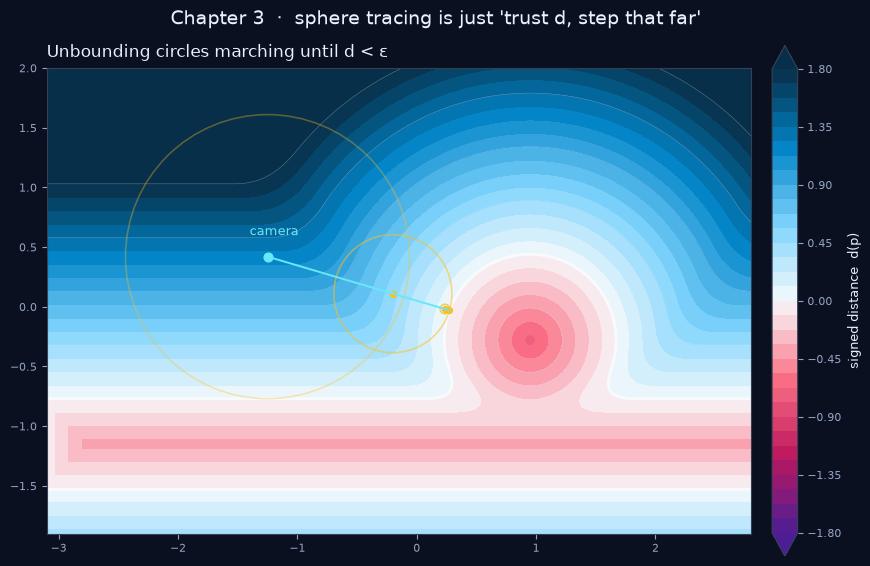

saved sdf-ch3-sphere-tracing.png


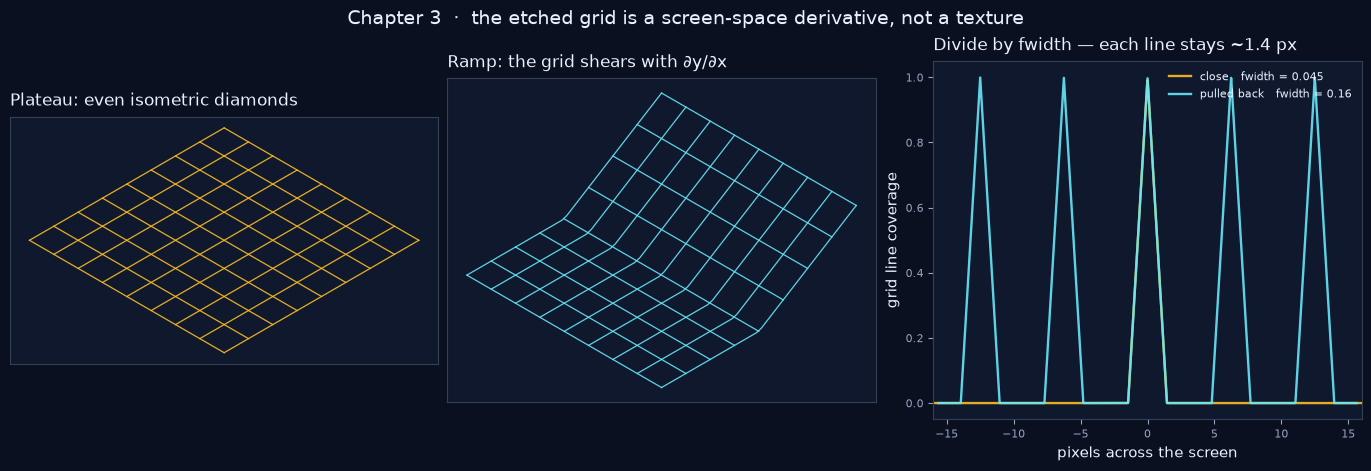

saved sdf-ch3-fwidth-grid.png
ch3_penumbra: 0.04465165071472176
ch3_ao_open: 1.0
ch3_ao_corner: 0.850040064102564


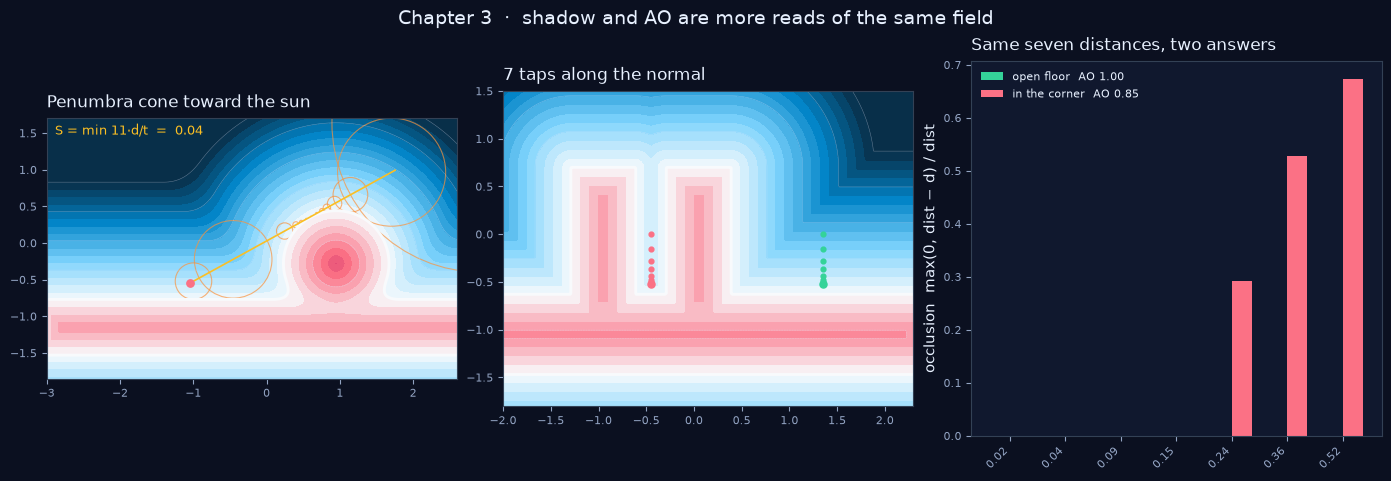

saved sdf-ch3-soft-shadow-ao.png
ch3_xray_hard_sign_flips: 2578
ch3_xray_smooth_sign_flips: 3308


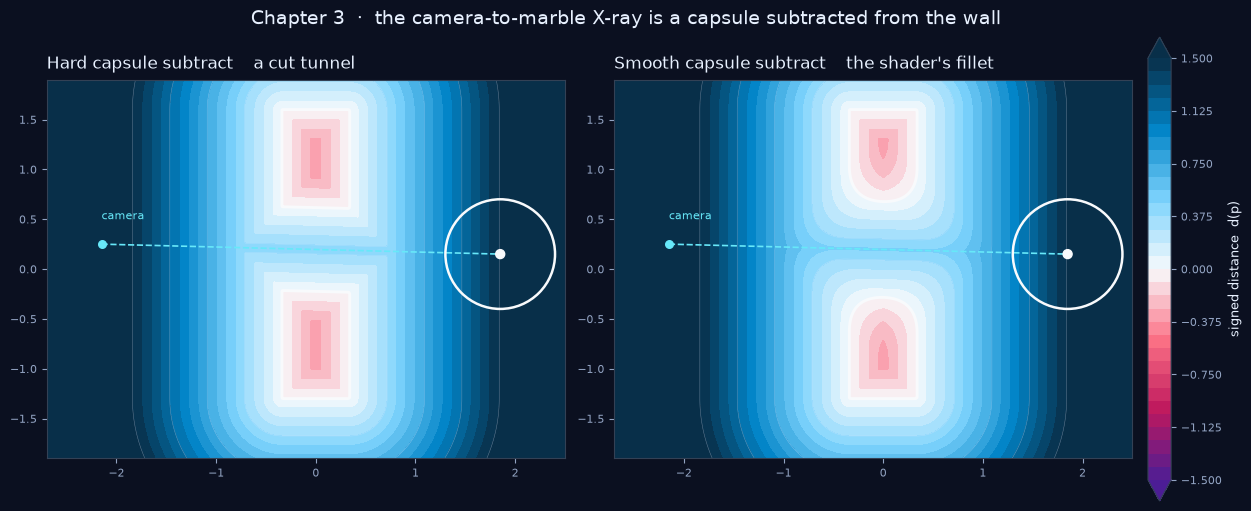

saved sdf-ch3-xray-capsule.png


In [4]:
def trace_scene(Q):
    ground = sd_box(Q, (3.3, 0.38), center=(0.15, -1.15))
    bump = sd_circle(Q, 0.72, center=(0.95, -0.28))
    return op_smooth_union(ground, bump, 0.28)


def march(sdf, origin, direction, steps=14, eps=0.02):
    direction = np.asarray(direction, float)
    direction = direction / np.linalg.norm(direction)
    origin = np.asarray(origin, float)
    t = 0.0
    pts = []
    radii = []
    for _ in range(steps):
        p = origin + t * direction
        d = float(sdf(p[None])[0])
        pts.append(p)
        radii.append(d)
        if d < eps:
            break
        t += max(0.92 * d, 0.0015)
    return np.vstack(pts), np.asarray(radii)


origin = np.array([-1.25, 0.42])
target = np.array([0.85, -0.2])
pts, radii = march(trace_scene, origin, target - origin)
metric("ch3_sphere_steps", int(len(pts)))
metric("ch3_sphere_final_d", float(radii[-1]))

fig, ax = plt.subplots(figsize=(8.6, 5.6), constrained_layout=True)
xlim, ylim = (-3.1, 2.8), (-1.9, 2.0)
X, Y = mesh(xlim, ylim, n=360)
cf = add_sdf(ax, X, Y, as_field(trace_scene, X, Y), "Unbounding circles marching until d < ε", v=1.8)
for i, (p, rad) in enumerate(zip(pts, radii)):
    alpha = 0.35 + 0.6 * (i / max(len(pts) - 1, 1))
    ax.add_patch(Circle(p, max(rad, 0.0), fill=False, ec=AMBER, lw=1.15, alpha=alpha, zorder=4))
    ax.scatter([p[0]], [p[1]], s=18, c=AMBER, zorder=5)
ax.plot(pts[:, 0], pts[:, 1], color=CYAN, lw=1.4, zorder=5)
ax.scatter([origin[0]], [origin[1]], s=40, c=CYAN, zorder=6)
ax.text(origin[0] - 0.15, origin[1] + 0.18, "camera", color=CYAN, fontsize=9)
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
colorbar(fig, cf, ax)
fig.suptitle("Chapter 3  ·  sphere tracing is just 'trust d, step that far'", fontsize=14, color=INK)
finish(fig, "sdf-ch3-sphere-tracing")


# fwidth: the pixel profile of a grid line does not move when the zoom changes.
def grid_mask(uv, fw):
    dist = np.abs(np.mod(uv - 0.5, 1.0) - 0.5)
    pix = dist / np.maximum(fw, 1e-4)
    return 1.0 - np.clip(pix / 1.45, 0.0, 1.0)


fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.6), constrained_layout=True)

def iso_project(x, y, z):
    sx = (x - z) * np.cos(np.deg2rad(30))
    sy = y + (x + z) * np.sin(np.deg2rad(30))
    return sx, sy

def draw_iso(ax, ramp=False):
    color = CYAN if ramp else AMBER
    for i in np.linspace(-2, 2, 9):
        xs = np.linspace(-2, 2, 40)
        zs = np.full_like(xs, i)
        ys = np.clip(0.62 * xs, 0, None) if ramp else np.zeros_like(xs)
        sx, sy = iso_project(xs, ys, zs)
        ax.plot(sx, sy, color=color, lw=0.9, alpha=0.9)
        xs = np.full_like(xs, i)
        zs = np.linspace(-2, 2, 40)
        ys = np.clip(0.62 * xs, 0, None) if ramp else np.zeros_like(xs)
        sx, sy = iso_project(xs, ys, zs)
        ax.plot(sx, sy, color=color, lw=0.9, alpha=0.9)
    dress(ax, "Ramp: the grid shears with ∂y/∂x" if ramp else "Plateau: even isometric diamonds")
    ax.set_xticks([])
    ax.set_yticks([])

draw_iso(axes[0], ramp=False)
draw_iso(axes[1], ramp=True)

ax = axes[2]
uv = np.linspace(-2.5, 2.5, 4000)
for fw, color, label in [(0.045, AMBER, "close   fwidth = 0.045"), (0.16, CYAN, "pulled back   fwidth = 0.16")]:
    pix = uv / fw
    # Plot against pixels so a constant pixel width lands on top of itself.
    sel = (pix > -18) & (pix < 18)
    ax.plot(pix[sel], grid_mask(uv[sel], fw), color=color, lw=1.7, label=label, alpha=0.9)
ax.set_xlim(-16, 16)
ax.set_xlabel("pixels across the screen")
ax.set_ylabel("grid line coverage")
dress(ax, "Divide by fwidth — each line stays ~1.4 px", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.suptitle("Chapter 3  ·  the etched grid is a screen-space derivative, not a texture", fontsize=14, color=INK)
finish(fig, "sdf-ch3-fwidth-grid")


def soft_shadow(sdf, ro, rd, steps=28, kpen=11.0):
    rd = np.asarray(rd, float)
    rd = rd / np.linalg.norm(rd)
    ro = np.asarray(ro, float)
    t = 0.06
    score = 1.0
    samples = []
    for _ in range(steps):
        p = ro + rd * t
        h = float(sdf(p[None])[0])
        samples.append((t, h, p))
        if h < 0.001:
            score = min(score, 0.08)
            break
        score = min(score, kpen * max(h, 0.0) / t)
        t += float(np.clip(h, 0.04, 0.7))
        if t > 8.0:
            break
    return score, samples


shade_ro = np.array([-1.05, -0.55])
bump_c = np.array([0.95, -0.28])
to_c = bump_c - shade_ro
u_c = to_c / np.linalg.norm(to_c)
perp = np.array([-u_c[1], u_c[0]])
# Aim just outside the bump so the march grazes and S lands in the penumbra, not at 0 or 1.
light_dir = (bump_c + perp * 0.78) - shade_ro
score, samples = soft_shadow(trace_scene, shade_ro, light_dir)
metric("ch3_penumbra", float(score))

# 7-tap AO on an open floor vs a crowded corner.
AO_DIST = np.array([0.02, 0.045, 0.085, 0.15, 0.24, 0.36, 0.52])
AO_W = np.array([0.22, 0.20, 0.17, 0.15, 0.11, 0.09, 0.06])


def corner_scene(Q):
    # A floor and two close walls: a slot. Upward samples stay near the walls, so AO drops.
    floor = sd_box(Q, (2.5, 0.42), center=(0.1, -1.05))
    left = sd_box(Q, (0.34, 0.85), center=(-0.95, -0.15))
    right = sd_box(Q, (0.34, 0.85), center=(0.05, -0.15))
    return op_union(op_union(floor, left), right)


def ao_taps(sdf, p, n):
    p = np.asarray(p, float)
    n = np.asarray(n, float)
    n = n / np.linalg.norm(n)
    occ = []
    for dist in AO_DIST:
        d = float(sdf((p + n * dist)[None])[0])
        occ.append(max(0.0, dist - d - 0.01) / dist)
    return np.asarray(occ)


def ao_value(occ):
    return float(np.clip(1.0 - np.sum(occ * AO_W) * 1.25, 0.32, 1.0))


open_p, open_n = np.array([1.35, -0.52]), np.array([0.0, 1.0])
corner_p, corner_n = np.array([-0.45, -0.52]), np.array([0.0, 1.0])
occ_open = ao_taps(corner_scene, open_p, open_n)
occ_corner = ao_taps(corner_scene, corner_p, corner_n)
metric("ch3_ao_open", ao_value(occ_open))
metric("ch3_ao_corner", ao_value(occ_corner))

fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.7), constrained_layout=True)
xlim, ylim = (-3.0, 2.6), (-1.85, 1.7)
X, Y = mesh(xlim, ylim, n=320)
cf = add_sdf(axes[0], X, Y, as_field(trace_scene, X, Y), "Penumbra cone toward the sun", v=1.6)
ld = light_dir / np.linalg.norm(light_dir)
axes[0].plot(
    [shade_ro[0], shade_ro[0] + ld[0] * 3.2],
    [shade_ro[1], shade_ro[1] + ld[1] * 3.2],
    color=AMBER, lw=1.2,
)
for t, h, p in samples[::2]:
    axes[0].add_patch(Circle(p, max(h, 0.0), fill=False, ec=ORANGE, lw=0.8, alpha=0.7))
axes[0].scatter([shade_ro[0]], [shade_ro[1]], c=PINK, s=28, zorder=6)
axes[0].text(0.02, 0.98, f"S = min 11·d/t  =  {score:.2f}", transform=axes[0].transAxes,
             color=AMBER, fontsize=9, va="top")
axes[0].set_xlim(*xlim)
axes[0].set_ylim(*ylim)

xlim, ylim = (-2.0, 2.3), (-1.8, 1.5)
X, Y = mesh(xlim, ylim, n=300)
add_sdf(axes[1], X, Y, as_field(corner_scene, X, Y), "7 taps along the normal", v=1.5)
for p, n, col in [(open_p, open_n, MINT), (corner_p, corner_n, PINK)]:
    n = n / np.linalg.norm(n)
    axes[1].scatter([p[0]], [p[1]], c=col, s=26, zorder=6)
    for dist in AO_DIST:
        q = p + n * dist
        axes[1].scatter([q[0]], [q[1]], c=col, s=12, zorder=5)
axes[1].set_xlim(*xlim)
axes[1].set_ylim(*ylim)

ax = axes[2]
idx = np.arange(len(AO_DIST))
ax.bar(idx - 0.18, occ_open, width=0.36, color=MINT, label=f"open floor  AO {ao_value(occ_open):.2f}")
ax.bar(idx + 0.18, occ_corner, width=0.36, color=PINK, label=f"in the corner  AO {ao_value(occ_corner):.2f}")
ax.set_xticks(idx)
ax.set_xticklabels([f"{d:.2f}" for d in AO_DIST], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("occlusion  max(0, dist − d) / dist")
dress(ax, "Same seven distances, two answers", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.suptitle("Chapter 3  ·  shadow and AO are more reads of the same field", fontsize=14, color=INK)
finish(fig, "sdf-ch3-soft-shadow-ao")


def xray_wall(Q):
    return sd_box(Q, (0.34, 1.45), center=(0.0, 0.15))


cam = np.array([-2.15, 0.25])
marble = np.array([1.85, 0.15])


def xray_hard(Q):
    return op_sub(xray_wall(Q), sd_capsule(Q, cam, marble, 0.42))


def xray_smooth(Q):
    return op_smooth_sub(xray_wall(Q), sd_capsule(Q, cam, marble, 0.48), 0.35)


# How much solid is removed: fraction of samples that flip from inside to outside.
X, Y = mesh((-2.7, 2.5), (-1.9, 1.9), n=300)
Dh = as_field(xray_hard, X, Y)
Ds = as_field(xray_smooth, X, Y)
Dw = as_field(xray_wall, X, Y)
metric("ch3_xray_hard_sign_flips", int(np.sum((Dw < 0) & (Dh > 0))))
metric("ch3_xray_smooth_sign_flips", int(np.sum((Dw < 0) & (Ds > 0))))

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.0), constrained_layout=True)
for ax, D, title in [
    (axes[0], Dh, "Hard capsule subtract    a cut tunnel"),
    (axes[1], Ds, "Smooth capsule subtract    the shader's fillet"),
]:
    cf = add_sdf(ax, X, Y, D, title, v=1.5)
    ax.plot([cam[0], marble[0]], [cam[1], marble[1]], color=CYAN, lw=1.2, ls="--")
    ax.scatter([cam[0]], [cam[1]], c=CYAN, s=30, zorder=6)
    draw_marble(ax, marble)
    ax.text(cam[0], cam[1] + 0.25, "camera", color=CYAN, fontsize=8)
    ax.set_xlim(-2.7, 2.5)
    ax.set_ylim(-1.9, 1.9)
colorbar(fig, cf, axes[1])
fig.suptitle("Chapter 3  ·  the camera-to-marble X-ray is a capsule subtracted from the wall", fontsize=14, color=INK)
finish(fig, "sdf-ch3-xray-capsule")


## Chapter 4 — Physics SDF: the 120 Hz loop

Same function, now queried by a sphere of radius $R = 0.55$ at $1/120$ of a second.

The normal is not a 6-tap cross. It is the 4-tap tetrahedron from Paulo Falcao / Inigo Quilez, which is what `tetrahedralNormalFromFn` evaluates. Four corners, then normalize:

$$\mathbf{k} \in \{(1,-1,-1),(-1,-1,1),(-1,1,-1),(1,1,1)\}, \qquad \nabla d(\mathbf{p}) \propto \sum_i \mathbf{k}_i\, d(\mathbf{p} + h\mathbf{k}_i)$$

Build 0 uses $h = 0.0025$. When two union children are within `0.03` of each other, the solver also bias-picks the child whose normal still points up ($n_y \ge 0.68$), so a flush joint does not stub the toe. Chapter 2 was that bug, drawn.

Then the tick, in the order `stepFixed` actually runs it:

1. **`sphereCast`** when the step is longer than about half a radius. March the clearance $d - R$ along $\hat{\mathbf{v}}$ so a thin rail cannot be tunneled.
2. **Five depenetration iterations.** If $d < R$, push the center by $(R - d)$ along $\mathbf{n}$.
3. **Relative velocity** against a moving surface, $\mathbf{v}_{\mathrm{rel}} = \mathbf{v} - \mathbf{v}_{\mathrm{hazard}}$. Reflect the inward part. A rising wave or a piston hands its speed over in that one line.
4. **Slip versus grip.** The feel bible keeps $\boldsymbol{\omega}$ independent of $\mathbf{v}$ and measures contact slip $\mathbf{v}_{\mathrm{slip}} = \mathbf{v}_{\parallel} + R(\boldsymbol{\omega}\times\mathbf{n})$. Friction kills slip, up to $\tfrac{2}{7}\|\mathbf{v}_{\mathrm{slip}}\|$ for a solid sphere. Backspin is just $\boldsymbol{\omega}$ pointed the wrong way on purpose. (Build 0 still *writes* $\boldsymbol{\omega}$ from $\mathbf{v}$ at the end of the tick. The plots use the decoupled model, because that is the one the braking is designed around.)


ch4_tetra_angle_deg_h0025: 0.02944023284494145
ch4_tetra_angle_deg_h008: 0.9266497799573675


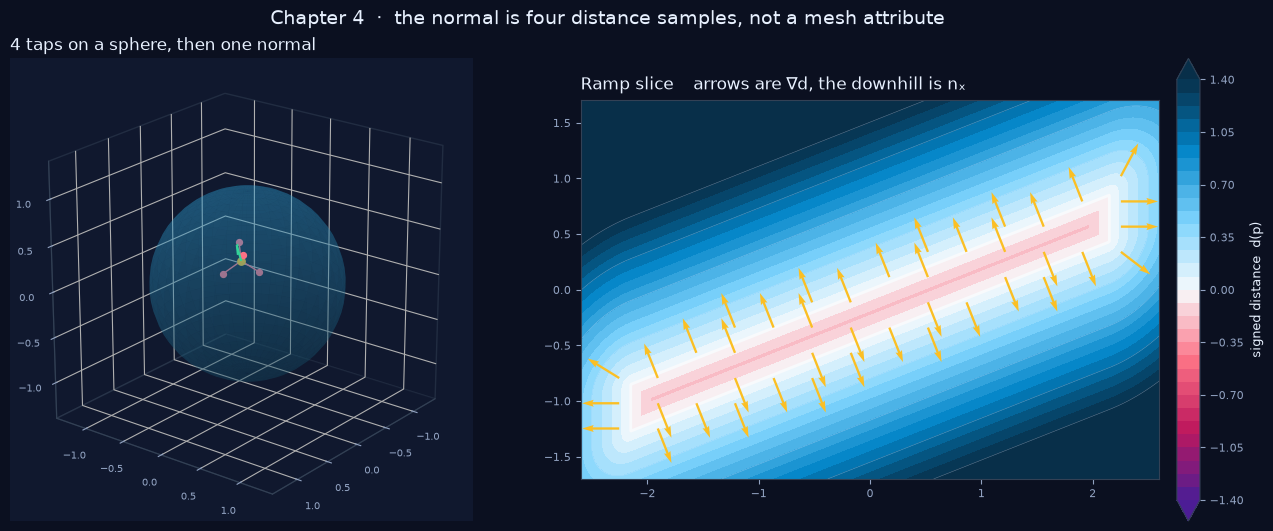

saved sdf-ch4-tetrahedral-gradient.png
ch4_ccd_hit: True
ch4_ccd_toi: 0.5502122585916989
ch4_naive_clearance: 0.4400000000000003
ch4_ccd_clearance: 0.006619126844449208
ch4_depen_iters: 2
ch4_depen_final_d_minus_R: 0.0014999999999998348


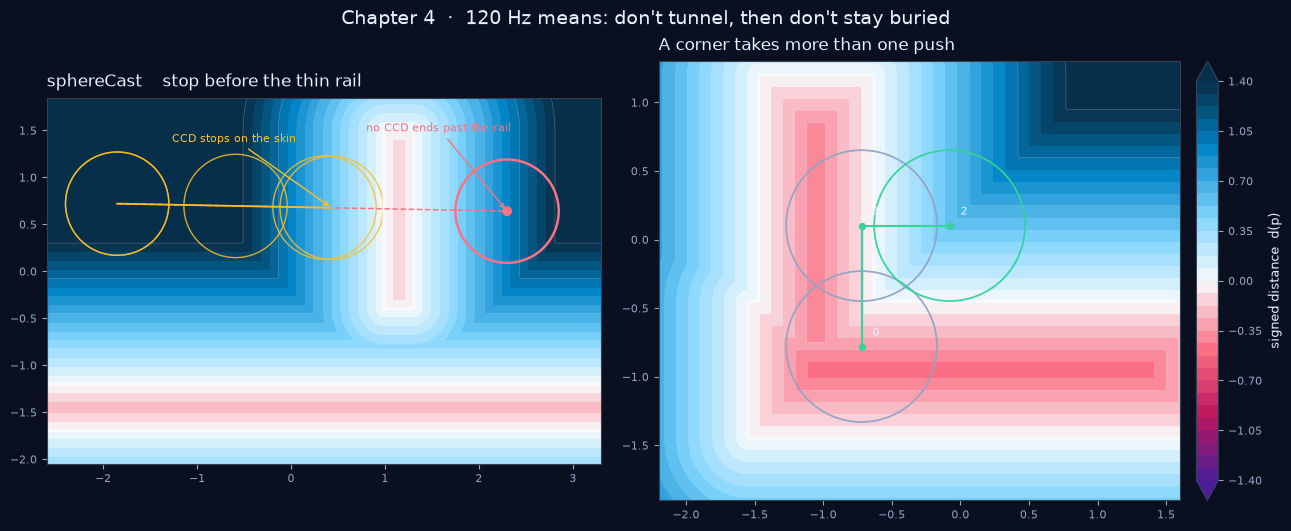

saved sdf-ch4-spherecast-depenetration.png
ch4_slip_grip: 0.0
ch4_slip_backspin: 18.8
ch4_backspin_slip_after_30_ticks_ice: 6.619999999999999
ch4_backspin_slip_after_30_ticks_track: 8.881784197001252e-16
ch4_backspin_slip_after_30_ticks_sticky: 2.220446049250313e-15


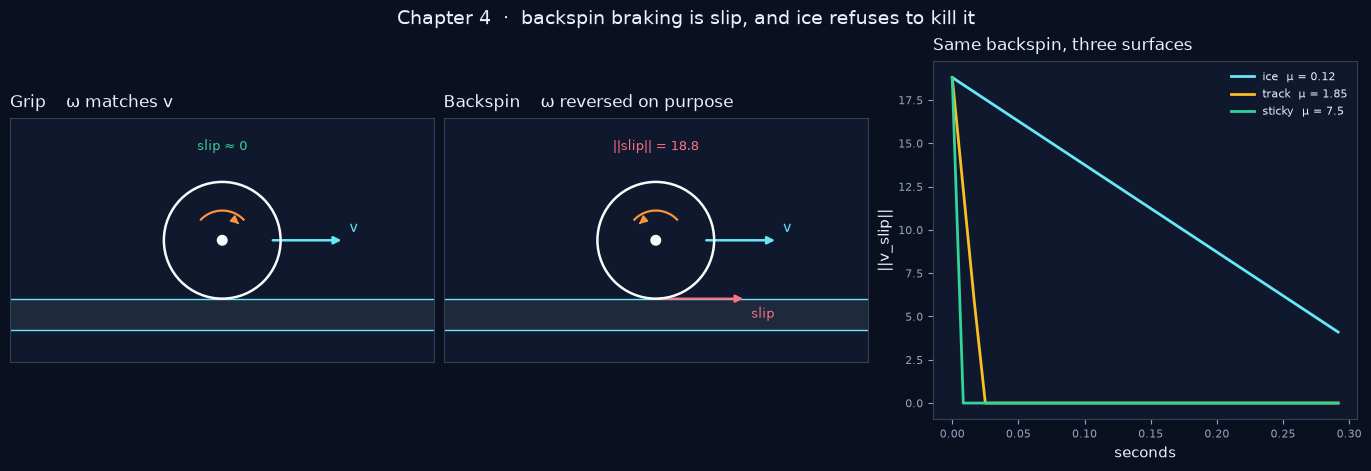

saved sdf-ch4-backspin-braking.png
ch4_wave_vy_on_rising_face: 1.32
ch4_wave_vy_after_transfer: 1.7200000000000002


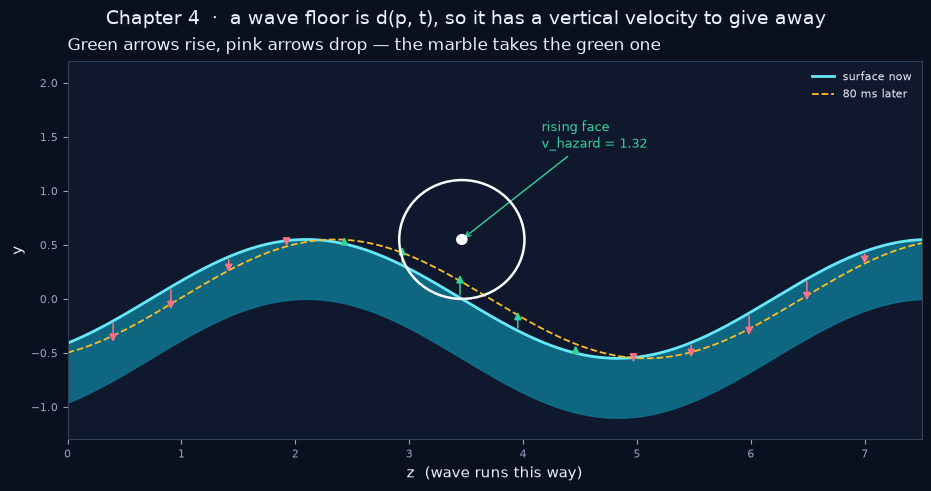

saved sdf-ch4-wave-floor.png


In [5]:
# 4-tap tetrahedral gradient vs the analytic radial normal of a sphere.
TETRA = np.array([
    [1.0, -1.0, -1.0],
    [-1.0, -1.0, 1.0],
    [-1.0, 1.0, -1.0],
    [1.0, 1.0, 1.0],
])


def sd_sphere3(p, r=1.0):
    p = np.asarray(p, float)
    return np.linalg.norm(p) - r


def tetra_grad(sdf3, p, h):
    p = np.asarray(p, float)
    acc = np.zeros(3)
    for k in TETRA:
        acc += k * sdf3(p + h * k)
    nrm = np.linalg.norm(acc)
    return acc / max(nrm, 1e-12)


probe = np.array([0.6, 0.4, 0.5])
analytic = probe / np.linalg.norm(probe)
est = tetra_grad(sd_sphere3, probe, h=0.0025)
cosang = float(np.clip(np.dot(analytic, est), -1, 1))
metric("ch4_tetra_angle_deg_h0025", float(np.degrees(np.arccos(cosang))))
est_fat = tetra_grad(sd_sphere3, probe, h=0.08)
metric("ch4_tetra_angle_deg_h008", float(np.degrees(np.arccos(np.clip(np.dot(analytic, est_fat), -1, 1)))))

# 2D slice quiver of the ramp, which is the normal the slope boost consumes.
fig = plt.figure(figsize=(13.2, 5.2), constrained_layout=True)
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
u = np.linspace(0, np.pi, 30)
v = np.linspace(0, 2 * np.pi, 40)
uu, vv = np.meshgrid(u, v)
sx = np.sin(uu) * np.cos(vv)
sy = np.sin(uu) * np.sin(vv)
sz = np.cos(uu)
ax3.plot_surface(sx, sy, sz, color="#38bdf8", alpha=0.25, linewidth=0, shade=True)
# Four taps, exaggerated so the tetrahedron reads, plus the normal they vote for.
surf_p = probe / np.linalg.norm(probe)
ax3.scatter([surf_p[0]], [surf_p[1]], [surf_p[2]], c=AMBER, s=28, depthshade=False)
ax3.quiver(surf_p[0], surf_p[1], surf_p[2], est[0], est[1], est[2], color=MINT, length=0.65, normalize=True)
for k in TETRA:
    q = surf_p + 0.22 * k / np.linalg.norm(k)
    ax3.plot([surf_p[0], q[0]], [surf_p[1], q[1]], [surf_p[2], q[2]], color=PINK, lw=1.0)
    ax3.scatter([q[0]], [q[1]], [q[2]], c=PINK, s=18, depthshade=False)
ax3.set_title("4 taps on a sphere, then one normal", loc="left", color=INK, fontsize=12)
ax3.set_xlim(-1.4, 1.4)
ax3.set_ylim(-1.4, 1.4)
ax3.set_zlim(-1.4, 1.4)
ax3.set_box_aspect((1, 1, 1))
for axis in (ax3.xaxis, ax3.yaxis, ax3.zaxis):
    axis.pane.set_facecolor(PANEL)
    axis.pane.set_edgecolor("#334155")
    axis.label.set_color(MUTED)
ax3.tick_params(colors=MUTED, labelsize=7)
ax3.view_init(elev=22, azim=38)

ax = fig.add_subplot(1, 2, 2)
xlim, ylim = (-2.6, 2.6), (-1.7, 1.7)
X, Y = mesh(xlim, ylim, n=300)
cf = add_sdf(ax, X, Y, as_field(sd_ramp, X, Y), "Ramp slice    arrows are ∇d, the downhill is nₓ", v=1.4)
normal_quiver(ax, sd_ramp, xlim, ylim, n=16, band=0.16, scale=3.0)
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
colorbar(fig, cf, ax)
fig.suptitle("Chapter 4  ·  the normal is four distance samples, not a mesh attribute", fontsize=14, color=INK)
finish(fig, "sdf-ch4-tetrahedral-gradient")


def thin_world(Q):
    floor = sd_box(Q, (4.6, 0.25), center=(0.4, -1.45))
    rail = sd_box(Q, (0.16, 0.95), center=(1.15, 0.55))
    return op_union(floor, rail)


cast_origin = np.array([-1.85, 0.72])
displacement = np.array([4.15, -0.08])
total = float(np.linalg.norm(displacement))
direction = displacement / total
marched = 0.0
cast_pts = [cast_origin.copy()]
hit = False
for _ in range(12):
    p = cast_origin + direction * marched
    margin = float(thin_world(p[None])[0]) - R_MARBLE
    cast_pts.append(p.copy())
    if margin <= 0.02:
        hit = True
        break
    step = max(0.92 * margin, 0.01)
    if marched + step >= total:
        marched = total
        cast_pts.append(cast_origin + displacement)
        break
    marched += step
cast_pts = np.vstack(cast_pts)
naive = cast_origin + displacement
metric("ch4_ccd_hit", bool(hit))
metric("ch4_ccd_toi", float(marched / total))
metric("ch4_naive_clearance", float(thin_world(naive[None])[0]) - R_MARBLE)
metric("ch4_ccd_clearance", float(thin_world(cast_pts[-1][None])[0]) - R_MARBLE)

def corner_world(Q):
    floor = sd_box(Q, (1.7, 0.5), center=(0.15, -0.95))
    wall = sd_box(Q, (0.42, 1.15), center=(-1.05, 0.05))
    return op_union(floor, wall)


# Buried in the floor/wall corner. Each push clears only the nearest face,
# so the marble needs more than one iteration to get free.
buried = np.array([-0.72, -0.78])
path = [buried.copy()]
c = buried.copy()
for _ in range(5):
    d = float(corner_world(c[None])[0])
    if d >= R_MARBLE:
        break
    g = grad2(corner_world, c[None])[0]
    n = g / max(np.linalg.norm(g), 1e-8)
    c = c + n * (R_MARBLE - d + 0.0015)
    path.append(c.copy())
path = np.vstack(path)
metric("ch4_depen_iters", int(len(path) - 1))
metric("ch4_depen_final_d_minus_R", float(corner_world(c[None])[0]) - R_MARBLE)

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2), constrained_layout=True)
xlim, ylim = (-2.6, 3.3), (-2.05, 1.85)
X, Y = mesh(xlim, ylim, n=340)
cf = add_sdf(axes[0], X, Y, as_field(thin_world, X, Y), "sphereCast    stop before the thin rail", v=1.5)
axes[0].plot([cast_origin[0], naive[0]], [cast_origin[1], naive[1]], color=PINK, lw=1.1, ls="--", zorder=4)
for p in cast_pts:
    axes[0].add_patch(Circle(p, R_MARBLE, fill=False, ec=AMBER, lw=1.0, alpha=0.85))
axes[0].plot(cast_pts[:, 0], cast_pts[:, 1], color=AMBER, lw=1.3, zorder=5)
draw_marble(axes[0], naive, color=PINK)
axes[0].annotate(
    "no CCD ends past the rail",
    xy=naive, xytext=(naive[0] - 1.5, naive[1] + 0.85),
    color=PINK, fontsize=8, arrowprops=dict(arrowstyle="->", color=PINK),
)
axes[0].annotate(
    "CCD stops on the skin",
    xy=cast_pts[-1], xytext=(cast_pts[-1, 0] - 1.7, cast_pts[-1, 1] + 0.7),
    color=AMBER, fontsize=8, arrowprops=dict(arrowstyle="->", color=AMBER),
)
axes[0].set_xlim(*xlim)
axes[0].set_ylim(*ylim)

Xc, Yc = mesh((-2.2, 1.6), (-1.9, 1.3), n=300)
cf2 = add_sdf(axes[1], Xc, Yc, as_field(corner_world, Xc, Yc), "A corner takes more than one push", v=1.4)
for i, p in enumerate(path):
    axes[1].add_patch(Circle(p, R_MARBLE, fill=False, ec=MINT if i == len(path) - 1 else MUTED, lw=1.3, alpha=0.95, zorder=5))
axes[1].plot(path[:, 0], path[:, 1], color=MINT, lw=1.5, zorder=6)
axes[1].scatter(path[:, 0], path[:, 1], c=MINT, s=18, zorder=7)
for i, p in enumerate(path):
    axes[1].text(p[0] + 0.08, p[1] + 0.08, str(i), color=INK, fontsize=8, zorder=8)
axes[1].set_xlim(-2.2, 1.6)
axes[1].set_ylim(-1.9, 1.3)
colorbar(fig, cf2, axes[1])
fig.suptitle("Chapter 4  ·  120 Hz means: don't tunnel, then don't stay buried", fontsize=14, color=INK)
finish(fig, "sdf-ch4-spherecast-depenetration")


def slip_state(v, omega, n, radius=R_MARBLE):
    v = np.asarray(v, float)
    omega = np.asarray(omega, float)
    n = np.asarray(n, float)
    n = n / np.linalg.norm(n)
    vt = v - np.dot(v, n) * n
    v_slip = vt + radius * np.cross(omega, n)
    return vt, v_slip


def friction_impulse(v_slip, mu, normal_load, dt=DT):
    mag = float(np.linalg.norm(v_slip))
    if mag < 1e-8:
        return np.zeros(3)
    cap = min(mu * normal_load * dt, (2.0 / 7.0) * mag)
    return -cap * v_slip / mag


n_up = np.array([0.0, 1.0, 0.0])
v_roll = np.array([8.0, 0.0, 0.0])
# Pure rolling: R (ω × n) = −v_tangent. For n = +Y and v = +X, ω = +Z * v/R.
omega_grip = np.array([0.0, 0.0, v_roll[0] / R_MARBLE])
omega_back = -1.35 * omega_grip
_, slip_grip = slip_state(v_roll, omega_grip, n_up)
_, slip_back = slip_state(v_roll, omega_back, n_up)
metric("ch4_slip_grip", float(np.linalg.norm(slip_grip)))
metric("ch4_slip_backspin", float(np.linalg.norm(slip_back)))

def step_contact(v, omega, mu, n=n_up, radius=R_MARBLE, load=G_BIBLE):
    # One Coulomb tick. J is applied to v and to omega, so slip falls by (7/2)||J||.
    _, v_slip = slip_state(v, omega, n, radius)
    J = friction_impulse(v_slip, mu, load)
    v = v + J
    omega = omega + (5.0 / (2.0 * radius)) * np.cross(n, J)
    return v, omega


histories = {}
for name, mu in [("ice", MU_ICE), ("track", MU_TRACK), ("sticky", MU_STICKY)]:
    v, w = v_roll.copy(), omega_back.copy()
    series = []
    for _ in range(36):
        _, s = slip_state(v, w, n_up)
        series.append(float(np.linalg.norm(s)))
        v, w = step_contact(v, w, mu)
    histories[name] = np.asarray(series)
    metric(f"ch4_backspin_slip_after_30_ticks_{name}", float(series[29]))


fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.6), constrained_layout=True)

def side_marble(ax, title, omega, slip, note, note_color):
    ax.add_patch(Polygon([[-2.2, -0.55], [2.2, -0.55], [2.2, -0.85], [-2.2, -0.85]], closed=True, fc="#1e293b", ec=CYAN, lw=1.0))
    c = np.array([0.0, 0.0])
    draw_marble(ax, c)
    # Spin arc
    w = omega[2]
    arc = np.linspace(-0.8, 0.8, 30) * np.sign(w if abs(w) > 1e-6 else 1)
    ax.plot(0.28 * np.sin(arc), 0.28 * np.cos(arc), color=ORANGE, lw=1.6)
    ax.annotate(
        "", xy=(0.22 * np.sin(arc[-1]), 0.22 * np.cos(arc[-1])),
        xytext=(0.22 * np.sin(arc[-4]), 0.22 * np.cos(arc[-4])),
        arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.4),
    )
    ax.annotate("", xy=(1.15, 0.0), xytext=(0.45, 0.0), arrowprops=dict(arrowstyle="-|>", color=CYAN, lw=1.8))
    ax.text(1.2, 0.08, "v", color=CYAN, fontsize=10)
    contact = np.array([0.0, -R_MARBLE])
    slip_2d = np.array([slip[0], slip[1]])
    if np.linalg.norm(slip_2d) > 0.2:
        sdir = slip_2d / np.linalg.norm(slip_2d)
        ax.annotate(
            "", xy=contact + sdir * 0.85, xytext=contact,
            arrowprops=dict(arrowstyle="-|>", color=PINK, lw=1.6),
        )
        ax.text(contact[0] + sdir[0] * 0.9, contact[1] - 0.18, "slip", color=PINK, fontsize=9)
    ax.text(0.0, 0.85, note, color=note_color, fontsize=9, ha="center")
    dress(ax, title)
    ax.set_xlim(-2.0, 2.0)
    ax.set_ylim(-1.15, 1.15)
    ax.set_xticks([])
    ax.set_yticks([])

side_marble(axes[0], "Grip    ω matches v", omega_grip, slip_grip, "slip ≈ 0", MINT)
side_marble(axes[1], "Backspin    ω reversed on purpose", omega_back, slip_back,
            f"||slip|| = {np.linalg.norm(slip_back):.1f}", PINK)

ax = axes[2]
ticks = np.arange(36) * DT
ax.plot(ticks, histories["ice"], color=CYAN, lw=2.0, label="ice  μ = 0.12")
ax.plot(ticks, histories["track"], color=AMBER, lw=2.0, label="track  μ = 1.85")
ax.plot(ticks, histories["sticky"], color=MINT, lw=2.0, label="sticky  μ = 7.5")
ax.set_xlabel("seconds")
ax.set_ylabel("||v_slip||")
dress(ax, "Same backspin, three surfaces", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.suptitle("Chapter 4  ·  backspin braking is slip, and ice refuses to kill it", fontsize=14, color=INK)
finish(fig, "sdf-ch4-backspin-braking")


# Traveling wave floor. Vertical surface speed is an analytic derivative, handed to the marble.
A_WAVE, K_WAVE, W_WAVE = 0.55, 1.15, 2.4


def wave_height(z, t):
    return A_WAVE * np.sin(K_WAVE * z - W_WAVE * t)


def wave_vy(z, t):
    return -A_WAVE * W_WAVE * np.cos(K_WAVE * z - W_WAVE * t)


t0 = 0.35
z_launch = (np.pi + W_WAVE * t0) / K_WAVE
vy_launch = float(wave_vy(z_launch, t0))
metric("ch4_wave_vy_on_rising_face", vy_launch)
# One tick of velocity transfer, bible form v ← v + v_hazard (already the relative-velocity reflect).
v_before = np.array([6.0, 0.4])
v_after = v_before + np.array([0.0, vy_launch])
metric("ch4_wave_vy_after_transfer", float(v_after[1]))

fig, ax = plt.subplots(figsize=(9.2, 4.8), constrained_layout=True)
zs = np.linspace(0.0, 7.5, 400)
ax.fill_between(zs, wave_height(zs, t0) - 0.55, wave_height(zs, t0), color="#0e7490", alpha=0.85)
ax.plot(zs, wave_height(zs, t0), color=CYAN, lw=2.0, label="surface now")
ax.plot(zs, wave_height(zs, t0 + 0.12), color=AMBER, lw=1.3, ls="--", label="80 ms later")
# Arrows of vertical surface velocity along the deck.
for z in np.linspace(0.4, 7.0, 14):
    y = wave_height(z, t0)
    vy = wave_vy(z, t0)
    ax.annotate(
        "", xy=(z, y + 0.18 * np.sign(vy) * min(abs(vy), 1.4)), xytext=(z, y),
        arrowprops=dict(arrowstyle="-|>", color=MINT if vy > 0 else PINK, lw=1.1),
    )
y_m = wave_height(z_launch, t0) + R_MARBLE
draw_marble(ax, (z_launch, y_m))
ax.annotate(
    f"rising face\nv_hazard = {vy_launch:.2f}",
    xy=(z_launch, y_m), xytext=(z_launch + 0.7, y_m + 0.85),
    color=MINT, fontsize=9, arrowprops=dict(arrowstyle="->", color=MINT),
)
ax.set_xlim(0, 7.5)
ax.set_ylim(-1.3, 2.2)
ax.set_xlabel("z  (wave runs this way)")
ax.set_ylabel("y")
dress(ax, "Green arrows rise, pink arrows drop — the marble takes the green one", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK, loc="upper right")
fig.suptitle("Chapter 4  ·  a wave floor is d(p, t), so it has a vertical velocity to give away", fontsize=14, color=INK)
finish(fig, "sdf-ch4-wave-floor")


## Chapter 5 — Living SDF: portals and a ring buffer of edits

Two toys that polygon engines make expensive, and a signed distance field gets for free.

**Portals.** A linked pair is a rigid transform. The raymarcher, on hitting the blue aperture, rewrites the ray and keeps marching — no second render target. The physics tick does the same rewrite to the marble:

$$\mathbf{v} \leftarrow \mathbf{R}_B\, \mathbf{R}_{y,\pi}\, \mathbf{R}_A^{-1}\, \mathbf{v}, \qquad \boldsymbol{\omega} \leftarrow \mathbf{R}_B\, \mathbf{R}_{y,\pi}\, \mathbf{R}_A^{-1}\, \boldsymbol{\omega}$$

Rotation preserves length. Fall into a floor portal at $25$ units per second and you leave the tilted orange portal at $25$, aimed along the exit. That is the fling. The plot below is the 2D version of that rewrite: $-\mathbf{n}_A$ maps to $\mathbf{n}_B$.

**Weapons.** `FieldMutation` is a 16-slot ring buffer shared by the CPU evaluator and the GPU shader. A crater is `smoothSubtract` of a sphere. A bridge is `smoothUnion` of a capsule. Nothing is remeshed. The next contour plot and the next tetrahedral normal are just the new function, evaluated on the next query. The isometric grid never had UVs, so it wraps the new surface by itself.


ch5_portal_speed_in: 25.317977802344327
ch5_portal_speed_out: 25.317977802344327
ch5_portal_speed_error: 0.0
ch5_portal_rotation_deg: 135.0


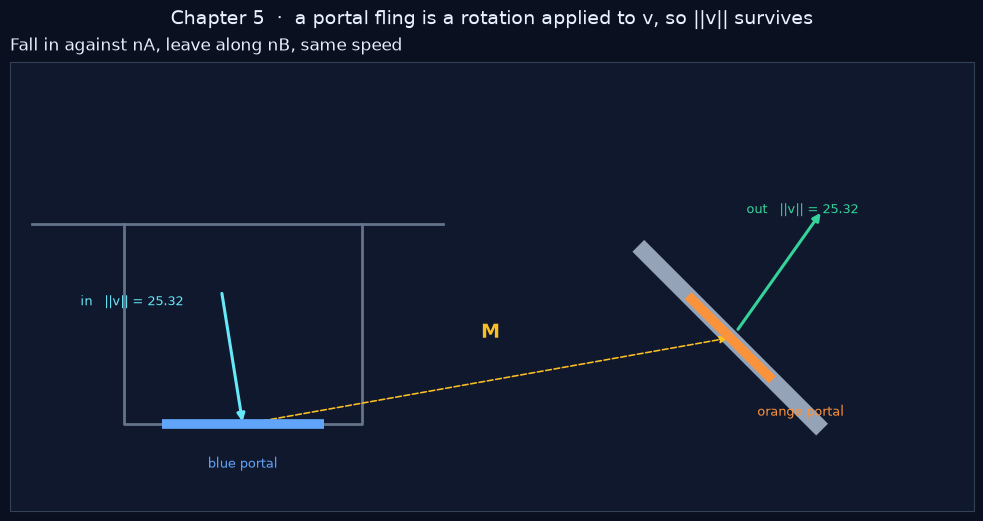

saved sdf-ch5-portals.png
ch5_crater_mean_abs_dny: 0.7026174746683753
ch5_bridge_extends_past_deck: True


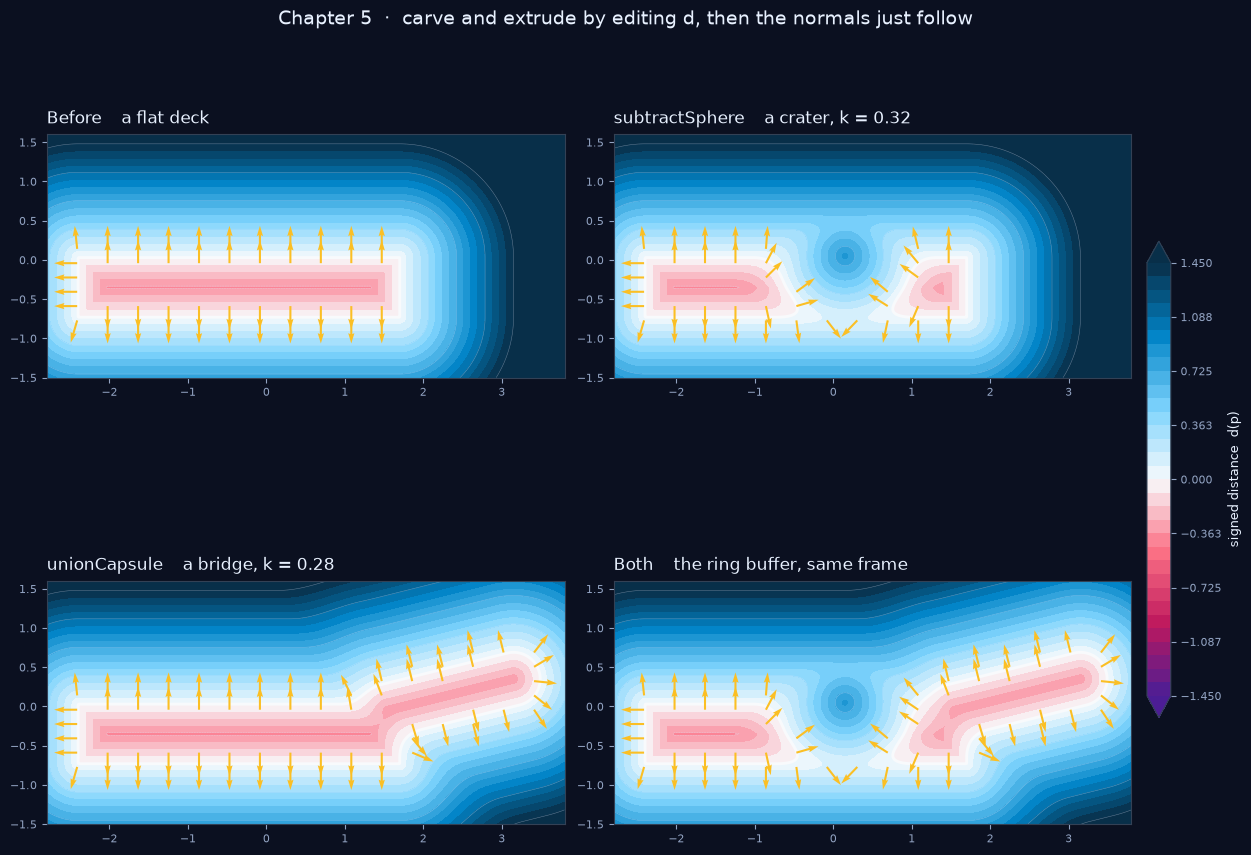

saved sdf-ch5-field-mutations.png


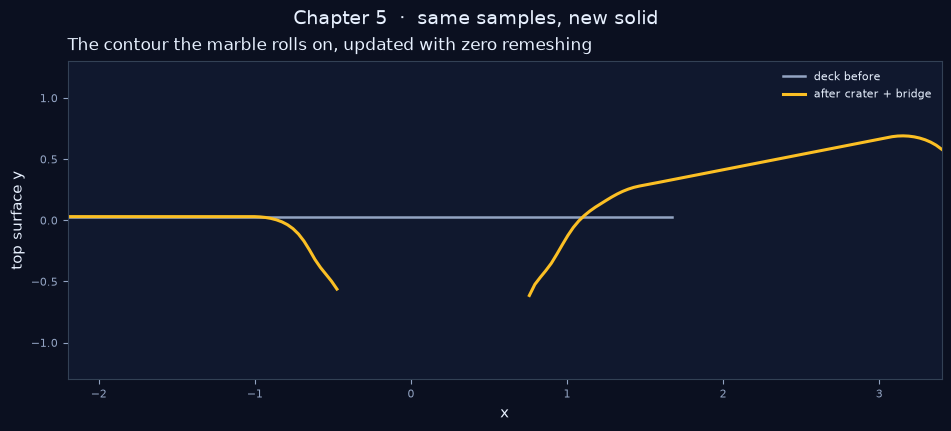

saved sdf-ch5-surface-profile.png
wrote /tmp/sdf-notebook-metrics.json
  ch1_eikonal_median_abs_err = 4.1977534614989764e-08
  ch1_eikonal_p95_abs_err = 3.800851304247544e-07
  ch1_true_push = 0.8
  ch1_squared_push = 0.9875
  ch1_true_residual_d_minus_R = 0.0
  ch1_squared_residual_d_minus_R = 0.1875
  ch2_hard_surface_jump = 1.0
  ch2_smooth_surface_jump = 0.098737946933388
  ch2_chute_hard_min_ny = -1.0
  ch2_chute_smooth_min_ny = -1.0
  ch3_sphere_steps = 4
  ch3_sphere_final_d = 0.0032887420831859693
  ch3_penumbra = 0.04465165071472176
  ch3_ao_open = 1.0
  ch3_ao_corner = 0.850040064102564
  ch3_xray_hard_sign_flips = 2578
  ch3_xray_smooth_sign_flips = 3308
  ch4_tetra_angle_deg_h0025 = 0.02944023284494145
  ch4_tetra_angle_deg_h008 = 0.9266497799573675
  ch4_ccd_hit = True
  ch4_ccd_toi = 0.5502122585916989
  ch4_naive_clearance = 0.4400000000000003
  ch4_ccd_clearance = 0.006619126844449208
  ch4_depen_iters = 2
  ch4_depen_final_d_minus_R = 0.0014999999999998348
  ch4_slip_g

In [6]:
def unit(v):
    v = np.asarray(v, float)
    return v / np.linalg.norm(v)


def rot_from_to(src, dst):
    s = unit(src)
    d = unit(dst)
    ang = np.arctan2(d[1], d[0]) - np.arctan2(s[1], s[0])
    c, sn = np.cos(ang), np.sin(ang)
    return np.array([[c, -sn], [sn, c]]), float(ang)


n_blue = np.array([0.0, 1.0])          # floor portal, normal up into the room
n_orange = unit(np.array([1.0, 1.0]))  # 45° exit, normal up-and-out
R_portal, ang = rot_from_to(-n_blue, n_orange)
v_in = np.array([4.0, -25.0])
v_out = R_portal @ v_in
metric("ch5_portal_speed_in", float(np.linalg.norm(v_in)))
metric("ch5_portal_speed_out", float(np.linalg.norm(v_out)))
metric("ch5_portal_speed_error", float(abs(np.linalg.norm(v_out) - np.linalg.norm(v_in))))
metric("ch5_portal_rotation_deg", float(np.degrees(ang)))

fig, ax = plt.subplots(figsize=(11.4, 5.1), constrained_layout=True)
ax.plot([-0.3, 3.5], [0.2, 0.2], color="#64748b", lw=2.0)
ax.plot([0.55, 0.55, 2.75, 2.75], [0.2, -1.65, -1.65, 0.2], color="#64748b", lw=2.0)
ax.plot([0.9, 2.4], [-1.65, -1.65], color=BLUE, lw=7, solid_capstyle="butt", zorder=4)
ax.text(1.65, -2.05, "blue portal", color=BLUE, ha="center", fontsize=9)
t_hat = np.array([-n_orange[1], n_orange[0]])
base = np.array([6.15, -0.85])
wall_a = base - t_hat * 1.2
wall_b = base + t_hat * 1.2
ax.plot([wall_a[0], wall_b[0]], [wall_a[1], wall_b[1]], color="#94a3b8", lw=12, solid_capstyle="butt", zorder=3)
ax.plot(
    [base[0] - t_hat[0] * 0.55, base[0] + t_hat[0] * 0.55],
    [base[1] - t_hat[1] * 0.55, base[1] + t_hat[1] * 0.55],
    color=ORANGE, lw=7, solid_capstyle="butt", zorder=4,
)
ax.text(base[0] + 0.25, base[1] - 0.72, "orange portal", color=ORANGE, fontsize=9)
entry = np.array([1.65, -1.65])
ax.annotate(
    "", xy=entry, xytext=entry - unit(v_in) * 1.25,
    arrowprops=dict(arrowstyle="-|>", color=CYAN, lw=2.2),
)
ax.text(0.15, -0.55, f"in   ||v|| = {np.linalg.norm(v_in):.2f}", color=CYAN, fontsize=9)
ax.annotate(
    "", xy=base + unit(v_out) * 1.45, xytext=base + n_orange * 0.08,
    arrowprops=dict(arrowstyle="-|>", color=MINT, lw=2.2),
)
ax.text(base[0] + 0.15, base[1] + 1.15, f"out   ||v|| = {np.linalg.norm(v_out):.2f}", color=MINT, fontsize=9)
ax.annotate(
    "", xy=base, xytext=entry,
    arrowprops=dict(arrowstyle="-|>", color=AMBER, lw=1.15, ls="--"),
)
ax.text(3.85, -0.85, "M", color=AMBER, fontsize=14, fontweight="bold")
ax.set_xlim(-0.5, 8.4)
ax.set_ylim(-2.45, 1.7)
dress(ax, "Fall in against nA, leave along nB, same speed")
ax.set_xticks([])
ax.set_yticks([])
fig.suptitle("Chapter 5  ·  a portal fling is a rotation applied to v, so ||v|| survives", fontsize=14, color=INK)
finish(fig, "sdf-ch5-portals")


def plateau(Q):
    deck = sd_box(Q, (2.05, 0.38), center=(-0.35, -0.35))
    return deck


def cratered(Q):
    return op_smooth_sub(plateau(Q), sd_circle(Q, 0.85, center=(0.15, 0.05)), 0.32)


def bridged(Q):
    cap = sd_capsule(Q, (1.55, -0.05), (3.15, 0.35), 0.34)
    return op_smooth_union(plateau(Q), cap, 0.28)


def mutated(Q):
    base = cratered(Q)
    cap = sd_capsule(Q, (1.55, -0.05), (3.15, 0.35), 0.34)
    return op_smooth_union(base, cap, 0.28)


xlim, ylim = (-2.8, 3.8), (-1.5, 1.6)
X, Y = mesh(xlim, ylim, n=340)
xs = np.linspace(-2.2, 3.4, 160)
y0 = top_surface(plateau, xs, ylim)
y1 = top_surface(mutated, xs, ylim)
# Normal swing at the crater lip, measured as change in ny.
lip = (xs > -0.4) & (xs < 0.8) & np.isfinite(y0) & np.isfinite(y1)
if np.any(lip):
    g0 = grad2(plateau, np.column_stack([xs[lip], y0[lip]]))
    g1 = grad2(mutated, np.column_stack([xs[lip], y1[lip]]))
    n0 = g0 / np.maximum(np.linalg.norm(g0, axis=1, keepdims=True), 1e-8)
    n1 = g1 / np.maximum(np.linalg.norm(g1, axis=1, keepdims=True), 1e-8)
    metric("ch5_crater_mean_abs_dny", float(np.mean(np.abs(n1[:, 1] - n0[:, 1]))))
else:
    metric("ch5_crater_mean_abs_dny", float("nan"))
metric("ch5_bridge_extends_past_deck", bool(np.nanmax(np.where(np.isfinite(y1), xs, -np.inf)) > 2.2))

fig, axes = plt.subplots(2, 2, figsize=(12.4, 9.2), constrained_layout=True)
for ax, fn, title in [
    (axes[0, 0], plateau, "Before    a flat deck"),
    (axes[0, 1], cratered, "subtractSphere    a crater, k = 0.32"),
    (axes[1, 0], bridged, "unionCapsule    a bridge, k = 0.28"),
    (axes[1, 1], mutated, "Both    the ring buffer, same frame"),
]:
    cf = add_sdf(ax, X, Y, as_field(fn, X, Y), title, v=1.45)
    normal_quiver(ax, fn, xlim, ylim, n=18, band=0.15, scale=3.4)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
colorbar(fig, cf, axes[:, 1])
fig.suptitle("Chapter 5  ·  carve and extrude by editing d, then the normals just follow", fontsize=14, color=INK)
finish(fig, "sdf-ch5-field-mutations")

fig, ax = plt.subplots(figsize=(9.4, 4.2), constrained_layout=True)
ax.plot(xs, y0, color=MUTED, lw=1.8, label="deck before")
ax.plot(xs, y1, color=AMBER, lw=2.2, label="after crater + bridge")
ax.set_xlim(-2.2, 3.4)
ax.set_ylim(-1.3, 1.3)
ax.set_xlabel("x")
ax.set_ylabel("top surface y")
dress(ax, "The contour the marble rolls on, updated with zero remeshing", equal=False)
ax.legend(frameon=False, fontsize=8, labelcolor=INK)
fig.suptitle("Chapter 5  ·  same samples, new solid", fontsize=14, color=INK)
finish(fig, "sdf-ch5-surface-profile")

METRICS_PATH.write_text(json.dumps(METRICS, indent=2))
print("wrote", METRICS_PATH)
for k, v in METRICS.items():
    print(f"  {k} = {v}")


## What to take back to the game

The video's last move is one sentence that covers every bug. Here is this notebook's version.

**The marble never hits a mesh. It hits $d$.** If $\|\nabla d\| = 1$, a push of $R - d$ is a real length. If a union is a hard $\min$, that length is fine and the *direction* still snags; $k$ in `opSmoothUnion` / `opSmoothSubtraction` is the term you turn to sand the seam, the chute lip, the crater rim, and the bridge root. Sphere tracing, the soft shadow, the 7-tap AO, and the X-ray capsule are extra rays through that same function. The 120 Hz tick is a sphere of radius $0.55$ doing a short cast, five pushes, and a relative-velocity reflect — which is how a wave, a piston, and a backspin brake all get to shove the marble without a special case. A portal is a rotation of $\mathbf{v}$ and $\boldsymbol{\omega}$. A weapon is one more row in a 16-long ring buffer.

Change one term. Look at the white curve and the arrows. That is the whole design tool.
